# YouTube Streamer Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Data exploration

We will be exploring and analyzing the Top 1000 Youtubers statistics to discover patterns, information and relationships between the best youtubers that can be used as insight later on.

We will first import the data and show the first 5 entries to understand the structure of the dataset. 

In [2]:
youtube = pd.read_csv('youtubers_df.csv')
youtube.head()

,Rank,Username,Categories,Suscribers,Country,Visits,Likes,Comments,Links
0,1,tseries,Música y baile,249500000.0,India,86200.0,2700.0,78.0,http://youtube.com/channel/UCq-Fj5jknLsUf-MWSy...
1,2,MrBeast,"Videojuegos, Humor",183500000.0,Estados Unidos,117400000.0,5300000.0,18500.0,http://youtube.com/channel/UCX6OQ3DkcsbYNE6H8u...
2,3,CoComelon,Educación,165500000.0,Unknown,7000000.0,24700.0,0.0,http://youtube.com/channel/UCbCmjCuTUZos6Inko4...
3,4,SETIndia,NaN,162600000.0,India,15600.0,166.0,9.0,http://youtube.com/channel/UCpEhnqL0y41EpW2TvW...
4,5,KidsDianaShow,"Animación, Juguetes",113500000.0,Unknown,3900000.0,12400.0,0.0,http://youtube.com/channel/UCk8GzjMOrta8yxDcKf...


In [3]:
youtube.shape

(1000, 9)

From this we see that we have 9 columns and 1000 records, hence we have 9000 entries. Below we observe more information on the columns and entries.

All columns, except from the 'Categories' columns which has 306 missing values, have no missing values. We can also see the data type of each column.

In [4]:
youtube.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Rank        1000 non-null   int64  
 1   Username    1000 non-null   object 
 2   Categories  694 non-null    object 
 3   Suscribers  1000 non-null   float64
 4   Country     1000 non-null   object 
 5   Visits      1000 non-null   float64
 6   Likes       1000 non-null   float64
 7   Comments    1000 non-null   float64
 8   Links       1000 non-null   object 
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


Below we see that (having checked for duplicates) we have 45 categories and 29 countries. It also shows some statistics on the other columns and theses stats show we have some variation in some of the variables.

In [5]:
youtube.duplicated().sum()

0

In [6]:
youtube.describe(include='all')

,Rank,Username,Categories,Suscribers,Country,Visits,Likes,Comments,Links
count,1000.000000,1000,694,1.000000e+03,1000,1.000000e+03,1.000000e+03,1000.000000,1000
unique,NaN,994,45,NaN,29,NaN,NaN,NaN,994
top,NaN,NickyJamTV,Música y baile,NaN,Estados Unidos,NaN,NaN,NaN,http://youtube.com/channel/UCpb_iJuhFe8V6rQdbN...
freq,NaN,2,160,NaN,293,NaN,NaN,NaN,2
mean,500.500000,NaN,NaN,2.189440e+07,NaN,1.209446e+06,5.363259e+04,1288.768000,NaN
std,288.819436,NaN,NaN,1.682775e+07,NaN,5.229942e+06,2.580457e+05,6778.188308,NaN
min,1.000000,NaN,NaN,1.170000e+07,NaN,0.000000e+00,0.000000e+00,0.000000,NaN
25%,250.750000,NaN,NaN,1.380000e+07,NaN,3.197500e+04,4.717500e+02,2.000000,NaN
50%,500.500000,NaN,NaN,1.675000e+07,NaN,1.744500e+05,3.500000e+03,67.000000,NaN
75%,750.250000,NaN,NaN,2.370000e+07,NaN,8.654750e+05,2.865000e+04,472.000000,NaN


Below we use boxplots to visually check for outliers one variable that we will call the performance metrics. We see that there are outliers, however based on the nature of the data that is to be expected therefore we will not be removing them.

<Axes: ylabel='Comments'>

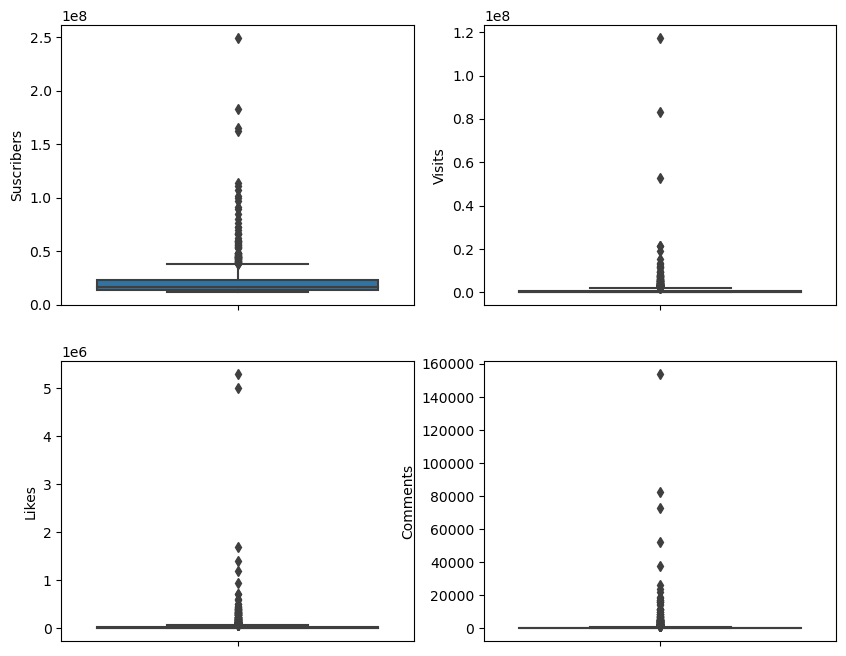

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
sns.boxplot(ax=axes[0, 0], data=youtube, y='Suscribers')
sns.boxplot(ax=axes[0, 1], data=youtube, y='Visits')
sns.boxplot(ax=axes[1, 0], data=youtube, y='Likes')
sns.boxplot(ax=axes[1, 1], data=youtube, y='Comments')

### Trend, Audience and Metrics analysis

Below we count the number of Youtube streamer per category and the find the top category among streamers is 'Música y baile' (Music and Dance) with 160 top streamers. Provided are the top 5 categories.

We also see, from the heatmap, that how top category is most popular in the countries 'Estados Unidos' (The united states) and 'India'.

In [8]:
cat = youtube['Categories'].value_counts()
cat.head()

Música y baile               160
Películas, Animación          61
Música y baile, Películas     41
Vlogs diarios                 37
Noticias y Política           36
Name: Categories, dtype: int64

<Axes: >

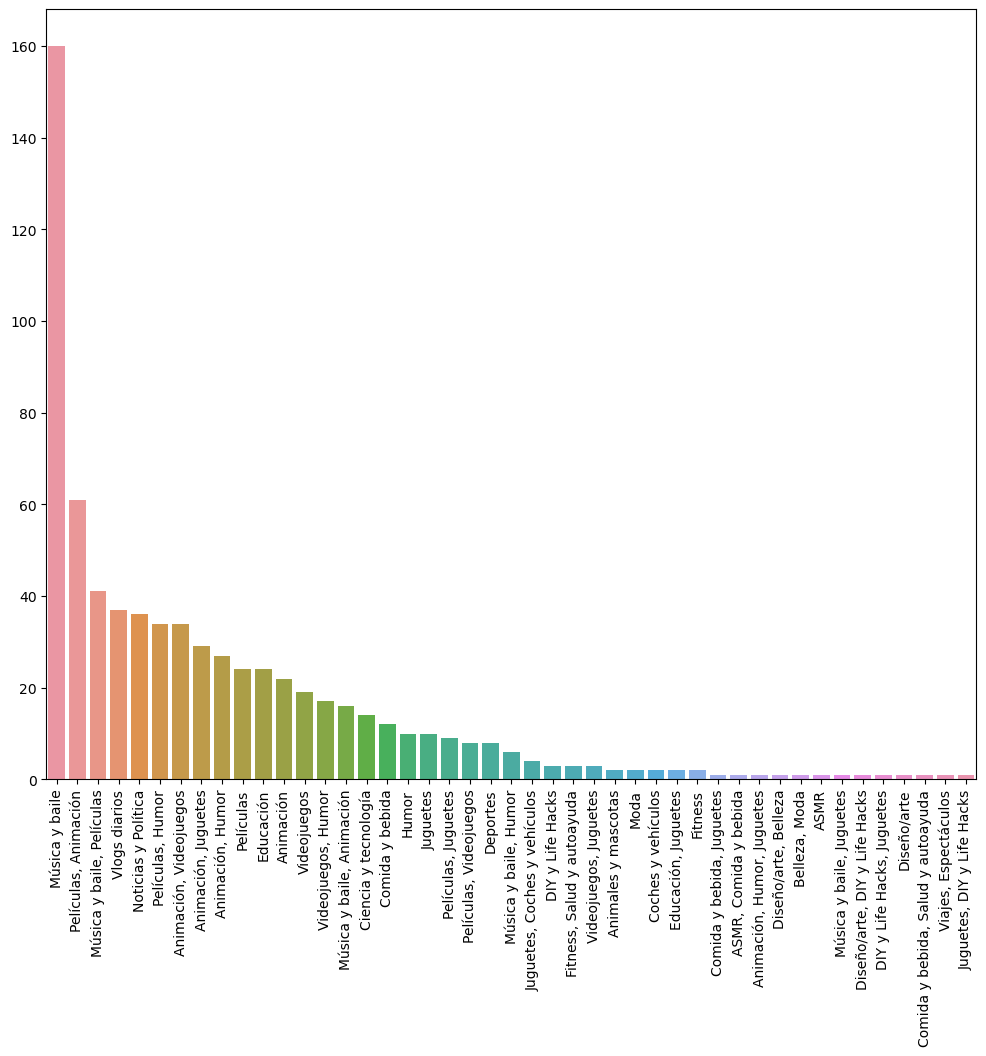

In [9]:
fig, ax = plt.subplots(figsize=(12,10))
ax.tick_params(axis='x', labelrotation=90)

keys = cat.index
counts = cat.values
sns.barplot(x=keys, y=counts)

<Axes: xlabel='None-Categories', ylabel='Country'>

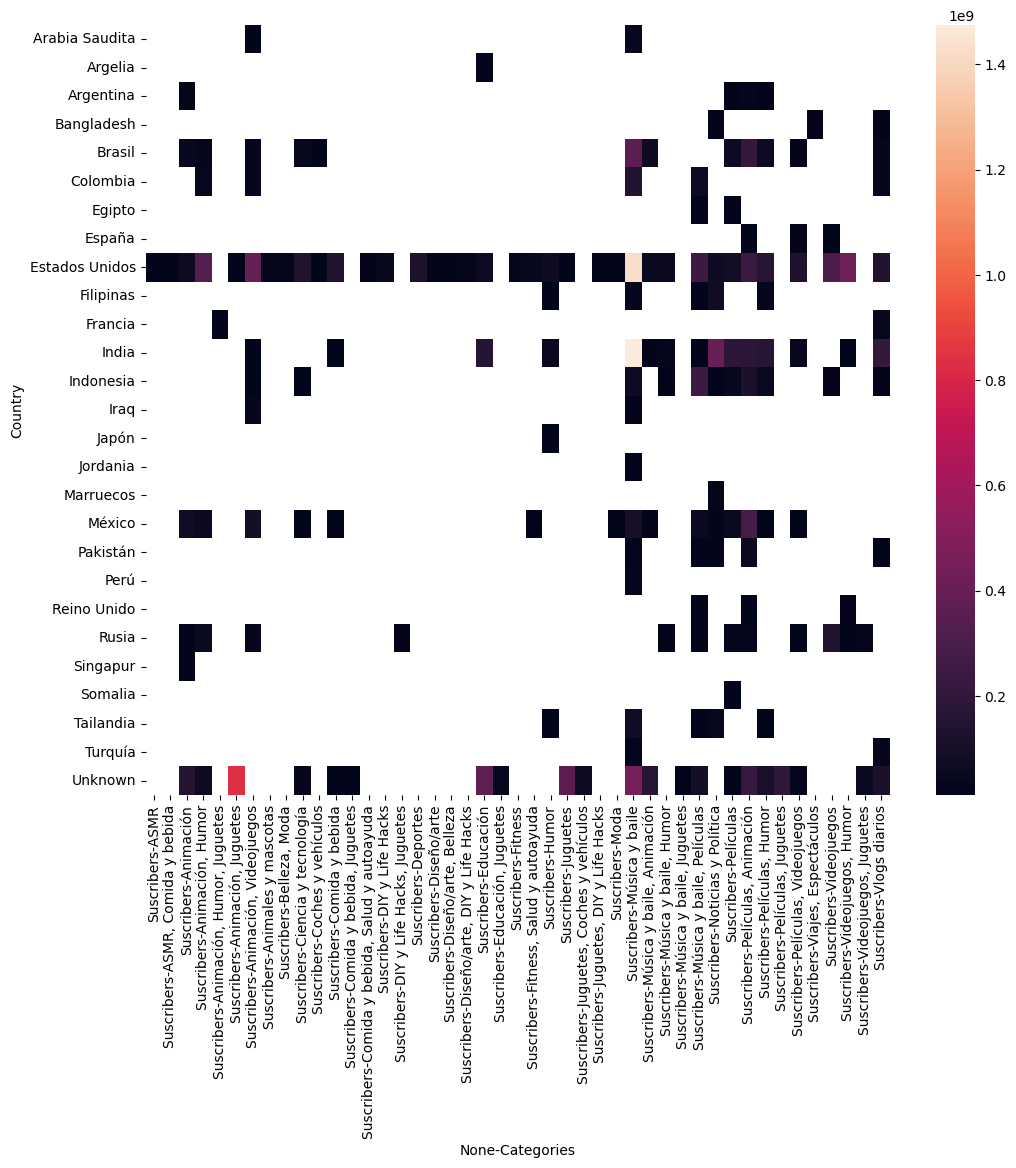

In [10]:
tbl = pd.pivot_table(youtube ,index=['Country'],columns=['Categories'],values=['Suscribers'],aggfunc=np.sum)

fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(tbl)

Below are the averages of the performance metrics and the correlation between them and we see that there is a strong correlation between the number of likes and the number of visits.

In [11]:
metrics = ['Suscribers', 'Visits', 'Likes', 'Comments']
means = {}

for x in metrics:
    means[x] = youtube[x].mean()
    print(youtube[x].mean())

21894400.0
1209446.3155
53632.592
1288.768


In [12]:
print(youtube[metrics].corr())

            Suscribers    Visits     Likes  Comments
Suscribers    1.000000  0.245203  0.211639  0.036350
Visits        0.245203  1.000000  0.950470  0.324067
Likes         0.211639  0.950470  1.000000  0.325911
Comments      0.036350  0.324067  0.325911  1.000000


We also see (based on the plot of the rank and subscribes), we see the streamers rank is based on how many subscribers they have but the number of likes, visits and comments is not strongly related to the rank and therefore not strongly related to the number of subscribers. This is also show above in the correlation matrix.

<Axes: xlabel='Rank', ylabel='Visits'>

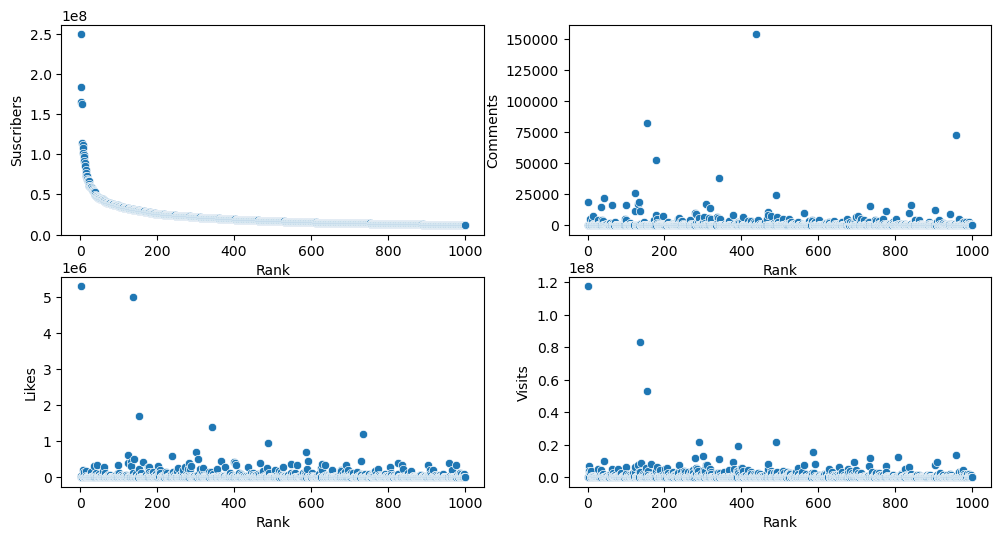

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
sns.scatterplot(ax=axes[0, 0], x=youtube.Rank, y=youtube.Suscribers)
sns.scatterplot(ax=axes[0, 1], x=youtube.Rank, y=youtube.Comments)
sns.scatterplot(ax=axes[1, 0], x=youtube.Rank, y=youtube.Likes)
sns.scatterplot(ax=axes[1, 1], x=youtube.Rank, y=youtube.Visits)

Provided below is the list of a streamers that a performing above the average of all the metrics despite of their rank. So in terms of metrics, these are the top performing content creator.

In [14]:
top = youtube[(youtube['Suscribers'] > means['Suscribers'])
                   & (youtube['Visits'] > means['Visits'])
                   & (youtube['Likes'] > means['Likes'])
                   & (youtube['Comments'] > means['Comments'])]
top

,Rank,Username,Categories,Suscribers,Country,Visits,Likes,Comments,Links
1,2,MrBeast,"Videojuegos, Humor",183500000.0,Estados Unidos,117400000.0,5300000.0,18500.0,http://youtube.com/channel/UCX6OQ3DkcsbYNE6H8u...
5,6,PewDiePie,"Películas, Videojuegos",111500000.0,Estados Unidos,2400000.0,197300.0,4900.0,http://youtube.com/channel/UC-lHJZR3Gqxm24_Vd_...
26,27,dudeperfect,Videojuegos,59700000.0,Estados Unidos,5300000.0,156500.0,4200.0,http://youtube.com/channel/UCRijo3ddMTht_IHyNS...
34,35,TaylorSwift,Música y baile,54100000.0,Estados Unidos,4300000.0,300400.0,15000.0,http://youtube.com/channel/UCqECaJ8Gagnn7YCbPE...
39,40,JuegaGerman,"Películas, Animación",48600000.0,México,2000000.0,117100.0,3000.0,http://youtube.com/channel/UCYiGq8XF7YQD00x7wA...
43,44,A4a4a4a4,"Animación, Humor",47300000.0,Rusia,9700000.0,330400.0,22000.0,http://youtube.com/channel/UC2tsySbe9TNrI-xh2l...
58,59,Mikecrack,"Películas, Animación",43400000.0,México,2200000.0,183400.0,1800.0,http://youtube.com/channel/UCqJ5zFEED1hWs0KNQC...
62,63,KimberlyLoaiza,Música y baile,42100000.0,México,5300000.0,271300.0,16000.0,http://youtube.com/channel/UCQZfFRohQ7UX-0CdXl...
64,65,luisitocomunica,NaN,41100000.0,México,2500000.0,128900.0,1800.0,http://youtube.com/channel/UCECJDeK0MNapZbpaOz...
70,71,JessNoLimit,"Películas, Animación",39600000.0,Indonesia,1300000.0,73500.0,1600.0,http://youtube.com/channel/UCvh1at6xpV1ytYOAzx...


### Recommendations

To enhance content recommendation, the use of the item item collaborative filtering method can be applied.

As example, given the information provided, using the preformance metrics of each streamer to find the correlation between the streamer and then make recommendations based on that.

In [15]:
usermetrics = youtube.pivot_table(columns=youtube['Username'])
usermetrics.head()

C:\Users\Ore\AppData\Local\Temp\ipykernel_7904\4225188111.py:1: FutureWarning: pivot_table dropped a column because it failed to aggregate. This behavior is deprecated and will raise in a future version of pandas. Select only the columns that can be aggregated.
  usermetrics = youtube.pivot_table(columns=youtube['Username'])


Username,-genevievesplayhouse1465,123GOSpanish,123GO_,1MILLION_Dance,1theK,5MCArabic,5MinuteCraftsDIY,5MinuteCraftsFAMILY,5MinuteCraftsLIKE,5MinuteCraftsPLAY,...,zbingz,zeebangla,zeemusiccompany,zeenews,zeetamil,zeetv,zeetvtelugu,zhong,zncoficial,zutigang
Comments,0.0,15.0,26.0,20.0,29.0,4.0,4.0,3.0,1.0,5.0,...,367.0,0.0,32.0,6.0,0.0,1.0,0.0,887.0,33.0,24.0
Likes,3100.0,547.0,549.0,1800.0,595.0,169.0,110.0,71.0,28.0,106.0,...,11300.0,17.0,2600.0,231.0,11.0,144.0,78.0,118300.0,1800.0,4900.0
Rank,332.0,734.0,916.0,194.0,227.0,562.0,326.0,563.0,993.0,346.0,...,447.0,655.0,9.0,131.0,825.0,17.0,691.0,136.0,611.0,567.0
Suscribers,20600000.0,13900000.0,12400000.0,26300000.0,24700000.0,15800000.0,20700000.0,15800000.0,11700000.0,20300000.0,...,17800000.0,14700000.0,99700000.0,32100000.0,13000000.0,72500000.0,14300000.0,31400000.0,15100000.0,15600000.0
Visits,513400.0,60400.0,133200.0,35300.0,10100.0,32500.0,14600.0,5200.0,2700.0,14300.0,...,458300.0,1300.0,74300.0,14700.0,1200.0,7300.0,2700.0,2900000.0,20400.0,124400.0


In [16]:
corrMatrix = usermetrics.corr()
corrMatrix.head()

Username,-genevievesplayhouse1465,123GOSpanish,123GO_,1MILLION_Dance,1theK,5MCArabic,5MinuteCraftsDIY,5MinuteCraftsFAMILY,5MinuteCraftsLIKE,5MinuteCraftsPLAY,...,zbingz,zeebangla,zeemusiccompany,zeenews,zeetamil,zeetv,zeetvtelugu,zhong,zncoficial,zutigang
Username,,,,,,,,,,,,,,,,,,,,,
-genevievesplayhouse1465,1.000000,0.999799,0.999904,0.999737,0.999716,0.999753,0.999723,0.999714,0.999711,0.999723,...,1.000000,0.999708,0.999724,0.999717,0.999708,0.999709,0.999711,0.997824,0.999736,0.999862
123GOSpanish,0.999799,1.000000,0.999981,0.999996,0.999993,0.999998,0.999994,0.999992,0.999992,0.999994,...,0.999786,0.999992,0.999994,0.999993,0.999992,0.999992,0.999992,0.996303,0.999996,0.999994
123GO_,0.999904,0.999981,1.000000,0.999958,0.999950,0.999965,0.999953,0.999949,0.999948,0.999953,...,0.999895,0.999947,0.999953,0.999950,0.999947,0.999947,0.999948,0.996817,0.999958,0.999996
1MILLION_Dance,0.999737,0.999996,0.999958,1.000000,1.000000,1.000000,1.000000,1.000000,0.999999,1.000000,...,0.999722,0.999999,1.000000,1.000000,0.999999,0.999999,0.999999,0.996050,1.000000,0.999980
1theK,0.999716,0.999993,0.999950,1.000000,1.000000,0.999999,1.000000,1.000000,1.000000,1.000000,...,0.999700,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.995970,1.000000,0.999974


Testing this with Mr beast, the system will provided the recommendation to the user of streamers similar (have a high correlation) to Mr Beast as shown below.

In [17]:
simCandidates = pd.Series()
for i in range(0, 1):
    sims = corrMatrix['MrBeast2']
    simCandidates = simCandidates.append(sims)
    
simCandidates.sort_values(inplace = True, ascending = False)
print (simCandidates.head())

MrBeast2             1.000000
DaFuqBoom            0.981005
BeastPhilanthropy    0.926394
dojacat              0.897754
_vector_             0.856753
dtype: float64


C:\Users\Ore\AppData\Local\Temp\ipykernel_7904\1257953577.py:1: FutureWarning: The default dtype for empty Series will be 'object' instead of 'float64' in a future version. Specify a dtype explicitly to silence this warning.
  simCandidates = pd.Series()
C:\Users\Ore\AppData\Local\Temp\ipykernel_7904\1257953577.py:4: FutureWarning: The series.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  simCandidates = simCandidates.append(sims)
